## 03: Modeling
Objective: build baselines, compare models with cross-validation on the training set, and evaluate the final model once on the test set.

### 1. Load Processed Data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_DIR = Path("../data/processed")

In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")["Survived"]
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["Survived"]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train survival rate:", round(y_train.mean() * 100, 1), "%")

Train: (712, 19) | Test: (179, 19)
Train survival rate: 38.3 %


### 2. Baselines

In [3]:
# Baseline 1: always predict "did not survive"
majority_pred = np.zeros(len(y_train), dtype=int)

# Baseline 2: simple rule - females survive, males do not
sex_rule_pred = X_train["Sex_female"].to_numpy()

baselines = pd.DataFrame({
    "accuracy": [(majority_pred == y_train).mean(), (sex_rule_pred == y_train).mean()],
    "f1": [f1_score(y_train, majority_pred, zero_division=0), f1_score(y_train, sex_rule_pred)],
}, index=["Always 'did not survive'", "Sex rule (female = survive)"]).round(3)

baselines

,accuracy,f1
Always 'did not survive',0.617,0.000
Sex rule (female = survive),0.789,0.715


## 3. Model Comparison with 5-Fold Cross-Validation

##### [Model builder]

In [4]:
def build_models(columns):
    """Return the three models. Logistic Regression scales the continuous
    columns inside a Pipeline, so the scaler is fitted only on each training fold."""
    scale_cols = [c for c in ["Age", "FamilySize", "Fare_log"] if c in columns]
    prep = ColumnTransformer([("scale", StandardScaler(), scale_cols)],
                             remainder="passthrough")
    return {
        "Logistic Regression": Pipeline([
            ("prep", prep),
            ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ]),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    }

#### [CV function]

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}


def evaluate(X, y):
    rows = {}
    for name, model in build_models(X.columns).items():
        res = cross_validate(model, X, y, cv=cv, scoring=scoring)
        rows[name] = {
            "accuracy_mean": res["test_accuracy"].mean(),
            "accuracy_std": res["test_accuracy"].std(),
            "f1_mean": res["test_f1"].mean(),
            "roc_auc_mean": res["test_roc_auc"].mean(),
        }
    return pd.DataFrame(rows).T.round(3)

#### [Run ar table]

In [6]:
cv_results = evaluate(X_train, y_train)
cv_results

,accuracy_mean,accuracy_std,f1_mean,roc_auc_mean
Logistic Regression,0.827,0.024,0.773,0.878
Random Forest,0.819,0.023,0.759,0.874
Gradient Boosting,0.820,0.029,0.755,0.894


##### [Chart (baseline-er sathe)]

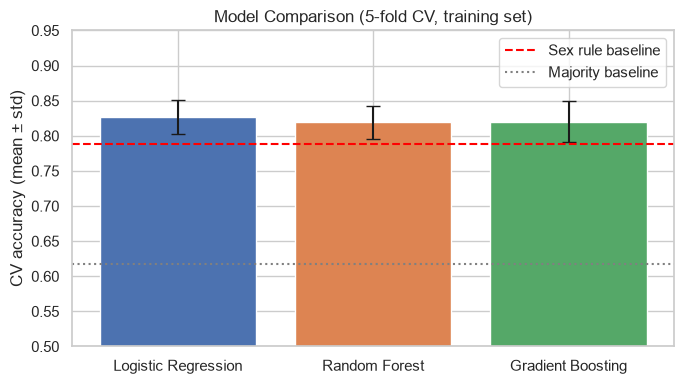

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cv_results.index, cv_results["accuracy_mean"],
       yerr=cv_results["accuracy_std"], capsize=5,
       color=sns.color_palette()[:3])
ax.axhline(baselines.loc["Sex rule (female = survive)", "accuracy"],
           color="red", linestyle="--", label="Sex rule baseline")
ax.axhline(baselines.loc["Always 'did not survive'", "accuracy"],
           color="gray", linestyle=":", label="Majority baseline")
ax.set_ylim(0.5, 0.95)
ax.set_ylabel("CV accuracy (mean ± std)")
ax.set_title("Model Comparison (5-fold CV, training set)")
ax.legend()
plt.tight_layout()
plt.show()

#### A simple Sex rule already gives about 79% accuracy. My three models reach about 82-83% in cross-validation, so they beat the baseline, but the gap between the models is smaller than the fold-to-fold variation. So I treat them as roughly equal and choose using other criteria, like ROC-AUC, simplicity, and tuning.

## 4. Feature Set Comparison
#### [Ablation run]

In [8]:
FAMILY_COLS = {
    "FamilySize": ["FamilySize"],
    "IsAlone": ["IsAlone"],
    "FamilyGroup": ["FamilyGroup_Alone", "FamilyGroup_Small", "FamilyGroup_Large"],
}

family_variants = {
    "all three": ["FamilySize", "IsAlone", "FamilyGroup"],
    "FamilySize only": ["FamilySize"],
    "IsAlone only": ["IsAlone"],
    "FamilyGroup only": ["FamilyGroup"],
    "no family features": [],
}

rows = []
for variant, keep in family_variants.items():
    for use_cabin in [True, False]:
        drop = [c for key, cols in FAMILY_COLS.items() if key not in keep for c in cols]
        if not use_cabin:
            drop.append("has_cabin")
        res = evaluate(X_train.drop(columns=drop), y_train)
        for model_name, r in res.iterrows():
            rows.append({
                "family": variant,
                "has_cabin": use_cabin,
                "model": model_name,
                "accuracy": r["accuracy_mean"],
                "roc_auc": r["roc_auc_mean"],
            })

ablation = pd.DataFrame(rows)
print("Done:", len(ablation), "results")

Done: 30 results


### [Accuracy table]

In [9]:
acc_table = ablation.pivot_table(index=["family", "has_cabin"], columns="model", values="accuracy")
acc_table["mean"] = acc_table.mean(axis=1)
acc_table.sort_values("mean", ascending=False).round(3)

,model,Gradient Boosting,Logistic Regression,Random Forest,mean
family,has_cabin,,,,
FamilyGroup only,True,0.833,0.826,0.822,0.827
FamilySize only,True,0.824,0.829,0.819,0.824
all three,True,0.820,0.827,0.819,0.822
no family features,True,0.827,0.816,0.808,0.817
FamilyGroup only,False,0.815,0.826,0.808,0.816
IsAlone only,True,0.823,0.813,0.813,0.816
all three,False,0.816,0.822,0.796,0.811
FamilySize only,False,0.813,0.819,0.798,0.810
IsAlone only,False,0.826,0.809,0.794,0.810


#### [ROC-AUC table]

In [10]:
auc_table = ablation.pivot_table(index=["family", "has_cabin"], columns="model", values="roc_auc")
auc_table["mean"] = auc_table.mean(axis=1)
auc_table.sort_values("mean", ascending=False).round(3)

,model,Gradient Boosting,Logistic Regression,Random Forest,mean
family,has_cabin,,,,
FamilyGroup only,True,0.891,0.880,0.875,0.882
FamilySize only,True,0.894,0.877,0.875,0.882
all three,True,0.894,0.878,0.874,0.882
FamilyGroup only,False,0.889,0.876,0.868,0.878
IsAlone only,True,0.889,0.870,0.874,0.878
all three,False,0.888,0.874,0.869,0.877
FamilySize only,False,0.889,0.873,0.868,0.877
no family features,True,0.889,0.867,0.871,0.876
IsAlone only,False,0.888,0.866,0.868,0.874


#### I compared feature sets with cross-validation on the training set only. The differences were small, within the noise, so I kept the simplest reasonable set: FamilySize and has_cabin. I did not use the test set for this decision.